# Temporal Feature Engineering con Pandas — UT3, Actividad 11

**Nombre:** Marcos Devincenzi  

## Objetivo y contrato de predicción
Después de completar una factura, predecir si el cliente realizará **otra compra en los próximos 30 días**. En ese momento conocemos el carrito actual, el calendario y el historial anterior. No conocemos compras posteriores. El horizonte explícito permite distinguir un negativo de un caso todavía no observado durante suficiente tiempo.

**Datos:** Online Retail de Kaggle (`vijayuv/onlineretail`). La descarga autenticada mediante la API de Kaggle está completada. El CSV coincide por SHA256 con los datos utilizados en el análisis.

**Correcciones necesarias de la guía:** las agregaciones de diversidad usan solo el pasado; recency no usa la fecha final del dataset; las publicaciones económicas tienen fecha de disponibilidad; las facturas simultáneas no se ordenan artificialmente como pasado; se purgan etiquetas que alcanzan el período de validación. Se compara AUC con AUC. `shift()` ayuda, pero por sí solo no garantiza ausencia de leakage.

## Setup y Carga de Datos
### Instalación de Librerías
La celda es opcional si el entorno ya tiene los paquetes. No se guardan credenciales en la entrega.

In [ ]:
# Ejecutar solo si faltan dependencias:
# %pip install pandas numpy scikit-learn matplotlib seaborn kaggle holidays ipywidgets statsmodels

In [1]:
from pathlib import Path
import json, os, zipfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import holidays
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import roc_auc_score, classification_report, average_precision_score
from sklearn.inspection import permutation_importance
from scipy.stats import linregress
from statsmodels.tsa.seasonal import seasonal_decompose

SEED = 42
HORIZON = pd.Timedelta(days=30)
DATA = Path('data')
OUTPUT = Path('temporal_resultados')
OUTPUT.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 12)
plt.style.use('seaborn-v0_8-whitegrid')
print('Pandas:', pd.__version__, '| horizonte:', HORIZON)

Pandas: 3.0.6 | horizonte: 30 days 00:00:00


## Parte 1: Cargar y Explorar Dataset
### 1.1 Cargar Online Retail Dataset desde Kaggle
**Formulario de autenticación local.** Ingresar solamente la ruta del archivo privado `kaggle.json`, por ejemplo `C:/Users/tu_usuario/.kaggle/kaggle.json`. El botón autentica y descarga. No imprime claves ni copia credenciales dentro de la entrega. En Colab se puede subir `kaggle.json` al entorno personal y colocar `/content/kaggle.json` en el formulario; eliminarlo antes de compartir archivos. Si el dataset ya está incluido, las otras celdas pueden ejecutarse sin credenciales, pero eso no reemplaza este requisito del profesor.

In [ ]:
import ipywidgets as widgets
from IPython.display import display

api_token = widgets.Password(description='API token:', placeholder='Token KGAT_… (no se guarda)', layout=widgets.Layout(width='650px'))
credential_path = widgets.Text(description='kaggle.json:', placeholder='Alternativa: ruta local de credenciales antiguas', layout=widgets.Layout(width='650px'))
download_button = widgets.Button(description='Autenticar y descargar', button_style='primary')
download_status = widgets.Output()

def download_authenticated(_):
    with download_status:
        download_status.clear_output()
        keys = ['KAGGLE_API_TOKEN', 'KAGGLE_USERNAME', 'KAGGLE_KEY']
        previous = {key: os.environ.get(key) for key in keys}
        credentials = {}
        try:
            token = api_token.value.strip()
            if token:
                os.environ['KAGGLE_API_TOKEN'] = token
                os.environ.pop('KAGGLE_USERNAME', None)
                os.environ.pop('KAGGLE_KEY', None)
            else:
                path = Path(credential_path.value).expanduser()
                if not path.is_file():
                    print('Ingresá tu token KGAT_… o la ruta de un kaggle.json privado.')
                    return
                credentials = json.loads(path.read_text(encoding='utf-8'))
                if not {'username', 'key'}.issubset(credentials):
                    print('El archivo debe contener username y key.')
                    return
                os.environ.pop('KAGGLE_API_TOKEN', None)
                os.environ['KAGGLE_USERNAME'] = credentials['username']
                os.environ['KAGGLE_KEY'] = credentials['key']
            from kaggle.api.kaggle_api_extended import KaggleApi
            api = KaggleApi()
            api.authenticate()
            api.dataset_download_files('vijayuv/onlineretail', path=str(DATA / 'online_retail'), force=True, unzip=True, quiet=True)
            print('Descarga autenticada completada. Credenciales eliminadas del formulario.')
        except Exception:
            print('No se pudo autenticar o descargar. Revisá token, conexión y permisos; no compartas claves.')
        finally:
            token = ''
            credentials.clear()
            for key, value in previous.items():
                if value is None:
                    os.environ.pop(key, None)
                else:
                    os.environ[key] = value
            api_token.value = ''
            credential_path.value = ''

download_button.on_click(download_authenticated)
display(widgets.VBox([api_token, credential_path, download_button, download_status]))

In [2]:
csv_path = DATA / 'online_retail' / 'OnlineRetail.csv'
if not csv_path.exists():
    candidates = list(DATA.rglob('*[Rr]etail*.csv'))
    if not candidates:
        raise FileNotFoundError('Descargá Online Retail con el formulario anterior.')
    csv_path = candidates[0]
raw = pd.read_csv(csv_path, encoding='ISO-8859-1', dtype={'InvoiceNo': str, 'StockCode': str})
print('Dimensiones originales:', raw.shape)
print('SHA256:', hashlib.sha256(csv_path.read_bytes()).hexdigest())
raw.info()
raw.head(10)

Dimensiones originales: (541909, 8)
SHA256: d07aec9960083af2339975a3f9d3b26313b342dcd9f86cce0b919b1cde639a44
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


### 1.2 Preparar y Explorar Estructura Temporal
Se eliminan clientes sin ID, cancelaciones y cantidades/precios no positivos. No se descartan automáticamente líneas duplicadas: podrían representar unidades o registros legítimos, y no conocemos su origen. El análisis de gaps se hace entre facturas, no entre productos de la misma factura. Fechas de este CSV en formato estadounidense: mes/día/año.

In [3]:
df = raw.dropna(subset=['CustomerID']).copy()
df = df.loc[~df.InvoiceNo.str.startswith('C') & (df.Quantity > 0) & (df.UnitPrice > 0)].copy()
df = df.rename(columns={'CustomerID': 'user_id', 'InvoiceDate': 'order_date', 'InvoiceNo': 'order_id', 'StockCode': 'product_id', 'UnitPrice': 'price'})
df['user_id'] = df.user_id.astype('int64').astype(str)
df['order_date'] = pd.to_datetime(df.order_date, format='%m/%d/%Y %H:%M')
df['total_amount'] = df.Quantity * df.price
df = df.sort_values(['user_id', 'order_date', 'order_id']).reset_index(drop=True)
print('Líneas válidas:', len(df), '| clientes:', df.user_id.nunique())
print('Período:', df.order_date.min(), 'a', df.order_date.max())
print('Líneas duplicadas exactas:', df.duplicated().sum())
print('Órdenes por cliente:\n', df.groupby('user_id').order_id.nunique().describe())

Líneas válidas: 397884 | clientes: 4338
Período: 2010-12-01 08:26:00 a 2011-12-09 12:50:00
Líneas duplicadas exactas: 5192
Órdenes por cliente:
 count    4338.000000
mean        4.272015
std         7.697998
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       209.000000
Name: order_id, dtype: float64


### 1.3 Crear Features Derivadas a Nivel de Orden
`cart_size` cuenta líneas de producto, no unidades ni necesariamente productos distintos. `order_total` suma cantidad × precio. Se guarda también el conjunto de productos y países de cada factura para construir diversidad histórica después. Predecimos al cierre de la factura: su tamaño y total ya son conocidos.

Facturas: 18562 | fechas compartidas por cliente: 122


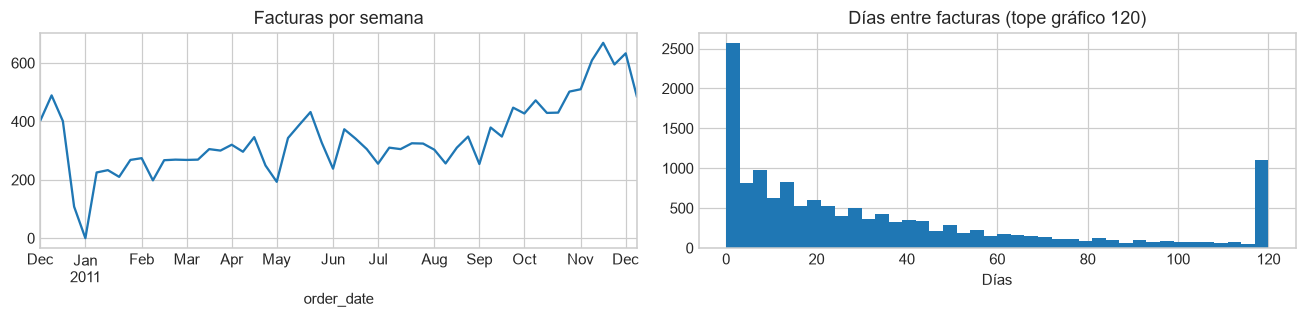

,user_id,order_id,order_date,cart_size,order_total,products,countries,order_number,days_since_prior_order,order_dow,order_hour_of_day
0,12346,541431,2011-01-18 10:01:00,1,77183.60,frozenset({23166}),frozenset({United Kingdom}),1,NaN,1,10
1,12347,537626,2010-12-07 14:57:00,31,711.79,"frozenset({21731, 22729, 85232D, 22805, 21171,...",frozenset({Iceland}),1,NaN,1,14
2,12347,542237,2011-01-26 14:30:00,29,475.39,"frozenset({22422, 21154, 21731, 22729, 22376, ...",frozenset({Iceland}),2,49.981250,2,14
3,12347,549222,2011-04-07 10:43:00,24,636.25,"frozenset({21731, 22376, 22371, 16008, 22492, ...",frozenset({Iceland}),3,70.842361,3,10
4,12347,556201,2011-06-09 13:01:00,18,382.52,"frozenset({23170, 23084, 23175, 22371, 23172, ...",frozenset({Iceland}),4,63.095833,3,13


In [4]:
orders = df.groupby(['user_id', 'order_id', 'order_date'], as_index=False).agg(
    cart_size=('product_id', 'count'), order_total=('total_amount', 'sum'),
    products=('product_id', lambda s: frozenset(s)), countries=('Country', lambda s: frozenset(s)))
orders = orders.sort_values(['user_id', 'order_date', 'order_id']).reset_index(drop=True)
orders['order_number'] = orders.groupby('user_id').cumcount() + 1
orders['days_since_prior_order'] = orders.groupby('user_id').order_date.diff().dt.total_seconds() / 86400
orders['order_dow'] = orders.order_date.dt.dayofweek
orders['order_hour_of_day'] = orders.order_date.dt.hour
print('Facturas:', len(orders), '| fechas compartidas por cliente:', orders.duplicated(['user_id', 'order_date']).sum())
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
orders.set_index('order_date').resample('W').size().plot(ax=ax[0], title='Facturas por semana')
orders.days_since_prior_order.dropna().clip(upper=120).hist(bins=40, ax=ax[1])
ax[1].set(title='Días entre facturas (tope gráfico 120)', xlabel='Días')
plt.tight_layout(); plt.show()
orders.head()

## Parte 2: Lag Features con Pandas
### 2.1 Crear Lag Features con `.shift()`
Se calcula primero la versión estándar ordenada por cliente. Más abajo se corrige el caso de facturas con la misma marca temporal: todas consultan el mismo historial **estrictamente anterior**; no suponemos cuál ocurrió primero dentro de ese minuto.

In [5]:
for lag in [1, 2, 3]:
    orders[f'days_since_prior_lag_{lag}'] = orders.groupby('user_id').days_since_prior_order.shift(lag)
    orders[f'cart_size_lag_{lag}'] = orders.groupby('user_id').cart_size.shift(lag)
    orders[f'order_total_lag_{lag}'] = orders.groupby('user_id').order_total.shift(lag)
orders[['user_id', 'order_date', 'cart_size', 'cart_size_lag_1']].head(8)

,user_id,order_date,cart_size,cart_size_lag_1
0,12346,2011-01-18 10:01:00,1,NaN
1,12347,2010-12-07 14:57:00,31,NaN
2,12347,2011-01-26 14:30:00,29,31.0
3,12347,2011-04-07 10:43:00,24,29.0
4,12347,2011-06-09 13:01:00,18,24.0
5,12347,2011-08-02 08:48:00,22,18.0
6,12347,2011-10-31 12:25:00,47,22.0
7,12347,2011-12-07 15:52:00,11,47.0


### 2.2 Rolling Window Features con Pandas
La media y desviación de las últimas tres facturas excluyen la factura actual. Una sola observación no permite estimar una desviación muestral: se conserva el NaN y se imputa dentro del modelo, con entrenamiento solamente.

In [6]:
orders['rolling_cart_mean_3'] = orders.groupby('user_id').cart_size.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
orders['rolling_cart_std_3'] = orders.groupby('user_id').cart_size.transform(lambda s: s.shift(1).rolling(3, min_periods=2).std())
orders['rolling_spend_mean_3'] = orders.groupby('user_id').order_total.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
orders[['cart_size', 'rolling_cart_mean_3', 'rolling_cart_std_3']].head(8)

,cart_size,rolling_cart_mean_3,rolling_cart_std_3
0,1,NaN,NaN
1,31,NaN,NaN
2,29,31.000000,NaN
3,24,30.000000,1.414214
4,18,28.000000,3.605551
5,22,23.666667,5.507571
6,47,21.333333,3.055050
7,11,29.000000,15.716234


### 2.3 Expanding Window Features con Pandas
Se acumula todo el pasado. `total_orders_so_far` excluye la factura actual. La primera factura tiene cero historia, no una historia inventada.

In [7]:
orders['expanding_days_mean'] = orders.groupby('user_id').days_since_prior_order.transform(lambda s: s.shift(1).expanding().mean())
orders['total_orders_so_far'] = orders.groupby('user_id').cumcount()
orders['expanding_total_spent'] = orders.groupby('user_id').order_total.transform(lambda s: s.shift(1).expanding().sum()).fillna(0)
orders[['total_orders_so_far', 'expanding_total_spent', 'expanding_days_mean']].head(8)

,total_orders_so_far,expanding_total_spent,expanding_days_mean
0,0,0.00,NaN
1,0,0.00,NaN
2,1,711.79,NaN
3,2,1187.18,49.981250
4,3,1823.43,60.411806
5,4,2205.95,61.306481
6,5,2790.86,59.435938
7,6,4085.18,65.578889


## Parte 3: RFM Analysis y Agregaciones por Usuario
### 3.1 RFM Features (Recency, Frequency, Monetary)
`recency_days` es el tiempo desde la última compra anterior hasta el instante de esta factura. Después de comprar, la recency literal sería cero; usamos la recency del historial justo anterior porque es informativa. Frequency cuenta compras anteriores; Monetary usa su gasto total y medio. Usar `fecha_final_dataset - fecha_factura` como recency sería conocer el futuro del archivo y medir su antigüedad, no el comportamiento histórico del usuario.

In [8]:
def historical_features(order_frame):
    """Todas las fuentes transaccionales cumplen source_time < order_time."""
    result = order_frame.sort_values(['user_id', 'order_date', 'order_id']).copy()
    result['history_max_date'] = pd.NaT
    zero_cols = ['total_orders_so_far', 'expanding_total_spent', 'monetary_total', 'frequency',
                 'unique_products', 'unique_countries', 'product_diversity_ratio',
                 'time_since_first_purchase', 'purchase_sessions_so_far'] + [f'{k}_{d}d' for d in [7, 30, 90] for k in ['orders', 'spend']]
    missing_cols = ['monetary_avg', 'recency_days', 'days_since_prior_order', 'expanding_days_mean',
                    'rolling_cart_mean_3', 'rolling_cart_std_3', 'rolling_spend_mean_3',
                    'past_spend_std', 'past_gap_std', 'spend_slope', 'frequency_slope'] + [f'{k}_lag_{n}' for k in ['days_since_prior', 'cart_size', 'order_total'] for n in [1, 2, 3]]
    result[zero_cols] = 0.
    result[missing_cols] = np.nan
    result['order_number'] = 1.
    # Clientes con una sola factura tienen historial vacío: resolverlos vectorizado.
    repeated = result.groupby('user_id').user_id.transform('size') > 1
    all_rows = []
    for _, g in result.loc[repeated].groupby('user_id', sort=False):
        times = g.order_date.to_numpy(dtype='datetime64[ns]')
        cart = g.cart_size.to_numpy(float)
        money = g.order_total.to_numpy(float)
        prefix = np.r_[0, money.cumsum()]
        gaps = np.r_[np.nan, np.diff(times) / np.timedelta64(1, 'D')]
        first = np.searchsorted(times, times, side='left')
        rows = []
        prior_products, prior_countries = set(), set()
        prior_lines = 0
        for start, block in g.groupby('order_date', sort=False):
            i = int(first[g.index.get_indexer([block.index[0]])[0]])
            values = {'total_orders_so_far': i, 'order_number': i + 1,
                      'expanding_total_spent': prefix[i], 'monetary_total': prefix[i],
                      'monetary_avg': prefix[i] / i if i else np.nan,
                      'frequency': i, 'recency_days': float((np.datetime64(start) - times[i-1]) / np.timedelta64(1, 'D')) if i else np.nan,
                      'days_since_prior_order': float((np.datetime64(start) - times[i-1]) / np.timedelta64(1, 'D')) if i else np.nan,
                      'expanding_days_mean': np.nanmean(gaps[:i]) if i > 1 else np.nan,
                      'rolling_cart_mean_3': cart[max(0, i-3):i].mean() if i else np.nan,
                      'rolling_cart_std_3': cart[max(0, i-3):i].std(ddof=1) if i > 1 else np.nan,
                      'rolling_spend_mean_3': money[max(0, i-3):i].mean() if i else np.nan,
                      'unique_products': len(prior_products), 'unique_countries': len(prior_countries),
                      'product_diversity_ratio': len(prior_products) / prior_lines if prior_lines else 0,
                      'history_max_date': pd.Timestamp(times[i-1]) if i else pd.NaT,
                      'time_since_first_purchase': float((np.datetime64(start) - times[0]) / np.timedelta64(1, 'D')),
                      'past_spend_std': money[:i].std(ddof=1) if i > 1 else np.nan,
                      'past_gap_std': np.nanstd(gaps[:i], ddof=1) if i > 2 else np.nan}
            for lag in [1, 2, 3]:
                values[f'days_since_prior_lag_{lag}'] = gaps[i-lag] if i >= lag else np.nan
                values[f'cart_size_lag_{lag}'] = cart[i-lag] if i >= lag else np.nan
                values[f'order_total_lag_{lag}'] = money[i-lag] if i >= lag else np.nan
            for days in [7, 30, 90]:
                left = np.searchsorted(times, np.datetime64(start) - np.timedelta64(days, 'D'), side='left')
                values[f'orders_{days}d'] = i - left
                values[f'spend_{days}d'] = prefix[i] - prefix[left]
            # Pendientes usan como máximo las últimas diez facturas anteriores.
            left = max(0, i-10)
            x = (times[left:i] - times[0]) / np.timedelta64(1, 'D')
            values['spend_slope'] = linregress(x, money[left:i]).slope if len(x) > 1 and np.ptp(x) > 0 else np.nan
            values['frequency_slope'] = linregress(x, np.arange(left, i)).slope if len(x) > 1 and np.ptp(x) > 0 else np.nan
            values['purchase_sessions_so_far'] = int((np.diff(times[:i]) > np.timedelta64(30, 'm')).sum() + 1) if i else 0
            for idx in block.index:
                rows.append({'index': idx, **values})
            for row in block.itertuples():
                prior_products.update(row.products)
                prior_countries.update(row.countries)
                prior_lines += row.cart_size
        all_rows.extend(rows)
    if all_rows:
        features = pd.DataFrame(all_rows).set_index('index')
        for col in features:
            result.loc[features.index, col] = features[col]
    return result

orders = historical_features(orders)
print('RFM y todas las agregaciones recalculadas con pasado estricto.')
orders[['user_id', 'order_date', 'recency_days', 'frequency', 'monetary_avg']].head(10)

RFM y todas las agregaciones recalculadas con pasado estricto.


,user_id,order_date,recency_days,frequency,monetary_avg
0,12346,2011-01-18 10:01:00,NaN,0.0,NaN
1,12347,2010-12-07 14:57:00,NaN,0.0,NaN
2,12347,2011-01-26 14:30:00,49.981250,1.0,711.790000
3,12347,2011-04-07 10:43:00,70.842361,2.0,593.590000
4,12347,2011-06-09 13:01:00,63.095833,3.0,607.810000
5,12347,2011-08-02 08:48:00,53.824306,4.0,551.487500
6,12347,2011-10-31 12:25:00,90.150694,5.0,558.172000
7,12347,2011-12-07 15:52:00,37.143750,6.0,680.863333
8,12348,2010-12-16 19:09:00,NaN,0.0,NaN
9,12348,2011-01-25 10:42:00,39.647917,1.0,892.800000


### 3.2 Time Window Aggregations (7d, 30d, 90d)
La función anterior usa intervalos `[t−ventana, t)` y búsquedas binarias. Así incluye el borde inferior y excluye todas las facturas simultáneas con t. Usa sumas acumuladas para el gasto. Los timestamps duplicados no hacen imposible usar rolling; lo que exige cuidado es el alineamiento del índice y el cierre del intervalo.

In [9]:
window_cols = [f'{kind}_{days}d' for days in [7, 30, 90] for kind in ['orders', 'spend']]
print(orders[window_cols].describe().round(2).to_string())
assert (orders.orders_7d <= orders.orders_30d).all()
assert (orders.orders_30d <= orders.orders_90d).all()
assert (orders.spend_7d <= orders.spend_30d + 1e-6).all()
assert (orders.spend_30d <= orders.spend_90d + 1e-6).all()
orders[['user_id', 'order_date'] + window_cols].tail(8)

       orders_7d  spend_7d  orders_30d  spend_30d  orders_90d  spend_90d
count   18562.00  18562.00    18562.00   18562.00    18562.00   18562.00
mean        0.41    289.73        1.41     917.98        3.68    2387.90
std         1.49   1774.13        3.53    3629.74        7.95    8405.19
min         0.00      0.00        0.00       0.00        0.00       0.00
25%         0.00      0.00        0.00       0.00        0.00       0.00
50%         0.00      0.00        0.00       0.00        1.00     397.20
75%         0.00      0.00        1.00     479.38        4.00    1291.10
max        33.00  68401.44       45.00   72612.64       88.00  123737.11


,user_id,order_date,orders_7d,spend_7d,orders_30d,spend_30d,orders_90d,spend_90d
18554,18283,2011-11-10 14:59:00,0.0,0.00,1.0,114.65,2.0,249.55
18555,18283,2011-11-10 15:07:00,1.0,112.35,2.0,227.00,3.0,361.90
18556,18283,2011-11-23 13:27:00,0.0,0.00,3.0,228.95,4.0,363.85
18557,18283,2011-11-30 12:59:00,1.0,313.65,3.0,427.95,5.0,677.50
18558,18283,2011-12-06 12:02:00,1.0,223.61,4.0,651.56,5.0,766.21
18559,18287,2011-05-22 10:39:00,0.0,0.00,0.0,0.00,0.0,0.00
18560,18287,2011-10-12 10:23:00,0.0,0.00,0.0,0.00,0.0,0.00
18561,18287,2011-10-28 09:29:00,0.0,0.00,1.0,1001.32,1.0,1001.32


### 3.3 Product Diversity Features
Los conjuntos de productos y países se actualizan después de calcular cada lote de facturas simultáneas. Contar todos los productos que el cliente comprará durante el año y unirlos a sus primeras facturas filtraría información futura. El ratio es productos históricos distintos / líneas históricas: no mide categorías, ausentes en el dataset.

       unique_products  unique_countries  product_diversity_ratio
count        18562.000         18562.000                18562.000
mean            92.272             0.767                    0.581
std            200.950             0.426                    0.373
min              0.000             0.000                    0.000
25%              3.000             1.000                    0.271
50%             35.000             1.000                    0.691
75%             90.000             1.000                    0.907
max           1773.000             2.000                    1.000


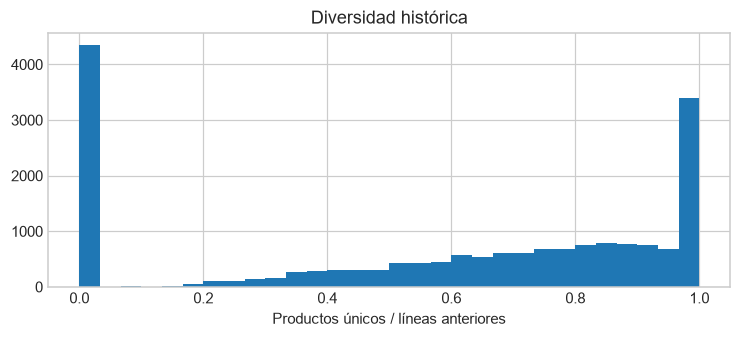

In [10]:
print(orders[['unique_products', 'unique_countries', 'product_diversity_ratio']].describe().round(3))
fig, ax = plt.subplots(figsize=(8, 3))
orders.product_diversity_ratio.hist(bins=30, ax=ax)
ax.set(title='Diversidad histórica', xlabel='Productos únicos / líneas anteriores')
plt.show()

## Parte 4: Calendar Features y External Variables
### 4.1 Calendar Features con Encoding Cíclico
Seno y coseno juntos permiten que 23:00 y 00:00 queden cerca. Los feriados futuros del calendario son información conocida, no compras futuras. La regla de la guía `day >= 25` representa la última semana comercial del mes, no el último día exacto; se incluyen ambas definiciones.

In [11]:
def calendar_features(frame, country='GB'):
    f = frame.copy()
    dt = f.order_date.dt
    f['order_dow'] = dt.dayofweek
    f['order_hour_of_day'] = dt.hour
    f['is_weekend'] = (dt.dayofweek >= 5).astype(int)
    f['day_of_month'] = dt.day
    f['is_month_end'] = (dt.day >= 25).astype(int)
    f['is_calendar_month_end'] = dt.is_month_end.astype(int)
    f['is_month_start'] = (dt.day <= 5).astype(int)
    f['month'] = dt.month
    f['quarter'] = dt.quarter
    uk = holidays.country_holidays(country, years=range(dt.year.min(), dt.year.max() + 2))
    holiday_dates = np.array(sorted(uk), dtype='datetime64[D]')
    dates = f.order_date.to_numpy(dtype='datetime64[D]')
    f['is_holiday'] = np.isin(dates, holiday_dates).astype(int)
    next_i = np.searchsorted(holiday_dates, dates)
    f['days_to_holiday'] = (holiday_dates[next_i] - dates) / np.timedelta64(1, 'D')
    for label, values, period in [('dow', dt.dayofweek, 7), ('hour', dt.hour, 24), ('month', dt.month - 1, 12)]:
        f[f'{label}_sin'] = np.sin(2 * np.pi * values / period)
        f[f'{label}_cos'] = np.cos(2 * np.pi * values / period)
    return f

orders = calendar_features(orders)
orders[['order_date', 'is_holiday', 'days_to_holiday', 'hour_sin', 'hour_cos']].head()

,order_date,is_holiday,days_to_holiday,hour_sin,hour_cos
0,2011-01-18 10:01:00,0,94.0,0.500000,-0.866025
1,2010-12-07 14:57:00,0,18.0,-0.500000,-0.866025
2,2011-01-26 14:30:00,0,86.0,-0.500000,-0.866025
3,2011-04-07 10:43:00,0,15.0,0.500000,-0.866025
4,2011-06-09 13:01:00,0,199.0,-0.258819,-0.965926


### 4.2 Economic Indicators (Simulados)
Se conserva la simulación de la consigna, con semilla 42. **No son cifras económicas reales y no permiten conclusiones causales.** Para mostrar disponibilidad, cada indicador mensual se publica el día 15 del mes siguiente. `merge_asof` trae la publicación más reciente que ya existía. Ni siquiera `ffill` evita leakage si se asignó antes un dato todavía no publicado. No se usa `bfill`.

In [12]:
rng = np.random.default_rng(SEED)
periods = pd.period_range(orders.order_date.min().to_period('M'), orders.order_date.max().to_period('M'), freq='M')
economic = pd.DataFrame({'month_period': periods.astype(str),
    'release_date': (periods + 1).to_timestamp() + pd.Timedelta(days=14),
    'gdp_growth': rng.normal(2.5, .5, len(periods)),
    'unemployment_rate': rng.normal(4, .3, len(periods)),
    'consumer_confidence': rng.normal(100, 5, len(periods))})
orders = pd.merge_asof(orders.sort_values('order_date'), economic.sort_values('release_date'), left_on='order_date', right_on='release_date', direction='backward').sort_values(['user_id', 'order_date', 'order_id']).reset_index(drop=True)
assert (orders.release_date.dropna() <= orders.loc[orders.release_date.notna(), 'order_date']).all()
print('Facturas sin indicador aún publicado:', orders.gdp_growth.isna().sum())
economic.head()

Facturas sin indicador aún publicado: 1834


,month_period,release_date,gdp_growth,unemployment_rate,consumer_confidence
0,2010-12,2011-01-15,2.652359,4.338172,102.661546
1,2011-01,2011-02-15,1.980008,4.140253,101.827220
2,2011-02,2011-03-15,2.875226,3.742212,102.063663
3,2011-03,2011-04-15,2.970282,4.110625,102.154105
4,2011-04,2011-05-15,1.524482,3.712335,110.708238


## Parte 5: Time-based Validation
### 5.1 Preparar Features para Modeling
La guía marca como positivo cualquier cliente con otra fila posterior y como negativo a su última fila. El final del archivo censura el futuro: no demuestra que el cliente nunca volverá. Se reemplaza ese target por **recompra dentro de 30 días**, y se excluyen observaciones sin 30 días completos de seguimiento. Las compras posteriores se usan solamente para construir y; nunca como X.

Las filas de clientes nuevos se mantienen. Los NaN de historia y de publicaciones tempranas se imputan usando exclusivamente el fold de entrenamiento, con indicadores de ausencia.

In [13]:
observed_end = orders.order_date.max()
orders['next_order_date'] = pd.NaT
for _, g in orders.groupby('user_id', sort=False):
    times = g.order_date.to_numpy(dtype='datetime64[ns]')
    nxt = np.searchsorted(times, times, side='right')
    next_dates = np.full(len(g), np.datetime64('NaT', 'ns'), dtype='datetime64[ns]')
    valid = nxt < len(g)
    next_dates[valid] = times[nxt[valid]]
    orders.loc[g.index, 'next_order_date'] = next_dates
orders['label_end'] = orders.order_date + HORIZON
orders['will_purchase_again'] = (orders.next_order_date.notna() & (orders.next_order_date <= orders.label_end)).astype(int)
eligible = orders.loc[orders.label_end <= observed_end].sort_values('order_date').reset_index(drop=True)
base_cols = ['cart_size', 'order_total', 'order_number']
lag_cols = [f'{kind}_lag_{i}' for kind in ['days_since_prior', 'cart_size', 'order_total'] for i in [1, 2, 3]]
rolling_cols = ['rolling_cart_mean_3', 'rolling_cart_std_3', 'rolling_spend_mean_3']
expanding_cols = ['expanding_days_mean', 'total_orders_so_far', 'expanding_total_spent']
rfm_cols = ['recency_days', 'frequency', 'monetary_avg', 'monetary_total']
diversity_cols = ['unique_products', 'unique_countries', 'product_diversity_ratio']
calendar_cols = ['order_dow', 'order_hour_of_day', 'is_weekend', 'day_of_month', 'is_month_end', 'is_calendar_month_end', 'is_month_start', 'quarter', 'is_holiday', 'days_to_holiday', 'dow_sin', 'dow_cos', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']
econ_cols = ['gdp_growth', 'unemployment_rate', 'consumer_confidence']
feature_cols = base_cols + lag_cols + rolling_cols + expanding_cols + rfm_cols + window_cols + diversity_cols + calendar_cols + econ_cols
assert len(feature_cols) == len(set(feature_cols))
assert not {'next_order_date', 'label_end', 'will_purchase_again', 'user_id'}.intersection(feature_cols)
test_start = eligible.order_date.max().normalize() - pd.Timedelta(days=59)
development = eligible.loc[eligible.label_end < test_start].copy()
test = eligible.loc[eligible.order_date >= test_start].copy()
final_train = development.loc[development.label_end < test_start].copy()
print('Facturas elegibles:', len(eligible), '| censuradas excluidas:', len(orders) - len(eligible))
print('Tasa de recompra 30d:', round(eligible.will_purchase_again.mean(), 4))
print('Desarrollo:', len(development), '| entrenamiento final maduro:', len(final_train), '| test:', len(test))
print('Inicio test:', test_start, '| cantidad de features:', len(feature_cols))

Facturas elegibles: 15822 | censuradas excluidas: 2740
Tasa de recompra 30d: 0.4563
Desarrollo: 10645 | entrenamiento final maduro: 10645 | test: 3890
Inicio test: 2011-09-11 00:00:00 | cantidad de features: 50


### 5.2 TimeSeriesSplit Validation
Se aplica `TimeSeriesSplit(n_splits=3)` sobre **días únicos**, no sobre filas arbitrarias. Luego se excluyen del entrenamiento las facturas cuya etiqueta de 30 días todavía no estaba disponible al empezar validación. Esta purga es adicional a ordenar las filas. El test de los últimos 60 días elegibles se reserva hasta terminar las decisiones.

In [14]:
def temporal_splits(frame, n_splits=3):
    days = np.sort(frame.order_date.dt.normalize().unique())
    splitter = TimeSeriesSplit(n_splits=n_splits)
    for train_days, val_days in splitter.split(days):
        start = pd.Timestamp(days[val_days[0]])
        tr = frame.index[(frame.order_date.dt.normalize().isin(days[train_days])) & (frame.label_end < start)].to_numpy()
        va = frame.index[frame.order_date.dt.normalize().isin(days[val_days])].to_numpy()
        assert frame.loc[tr, 'label_end'].max() < frame.loc[va, 'order_date'].min()
        yield tr, va

def new_model():
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True),
                         RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=10, max_features=.8, random_state=SEED, n_jobs=1))

folds = list(temporal_splits(development))
def evaluate(frame, columns, splits, label):
    rows = []
    for fold, (tr, va) in enumerate(splits, 1):
        train, validation = frame.loc[tr], frame.loc[va]
        model = new_model().fit(train[columns], train.will_purchase_again)
        p = model.predict_proba(validation[columns])[:, 1]
        train_p = model.predict_proba(train[columns])[:, 1]
        rows.append({'modelo': label, 'fold': fold, 'n_train': len(tr), 'n_val': len(va),
            'train_inicio': train.order_date.min(), 'train_fin': train.order_date.max(),
            'val_inicio': validation.order_date.min(), 'val_fin': validation.order_date.max(),
            'auc_train': roc_auc_score(train.will_purchase_again, train_p),
            'auc_val': roc_auc_score(validation.will_purchase_again, p),
            'ap_val': average_precision_score(validation.will_purchase_again, p)})
    return pd.DataFrame(rows)

full_cv = evaluate(development, feature_cols, folds, 'Temporal completo')
print(full_cv.round(4).to_string(index=False))

           modelo  fold  n_train  n_val        train_inicio           train_fin          val_inicio             val_fin  auc_train  auc_val  ap_val
Temporal completo     1     1713   2353 2010-12-01 08:26:00 2011-01-11 16:24:00 2011-02-11 08:45:00 2011-04-10 16:04:00     0.8841   0.7989  0.7901
Temporal completo     2     3866   2993 2010-12-01 08:26:00 2011-03-11 16:54:00 2011-04-11 08:14:00 2011-06-14 16:52:00     0.8964   0.8145  0.8218
Temporal completo     3     6622   2549 2010-12-01 08:26:00 2011-05-15 16:13:00 2011-06-15 08:34:00 2011-08-11 17:35:00     0.8932   0.8114  0.8258


### 5.3 Comparación: Con vs Sin Temporal Features
Se usan las mismas observaciones, particiones y algoritmo para el baseline y las features temporales. El baseline de la consigna ya incluye `order_number`, que resume historia; “sin temporal” significa aquí sin las nuevas features de historia/calendario/contexto. Se evalúa también quitar solamente los indicadores económicos simulados.

                       auc_media  auc_sd  ap_media
modelo                                            
Base de la guía           0.7940  0.0069    0.7773
Temporal completo         0.8083  0.0083    0.8126
Temporal sin economía     0.8073  0.0068    0.8113


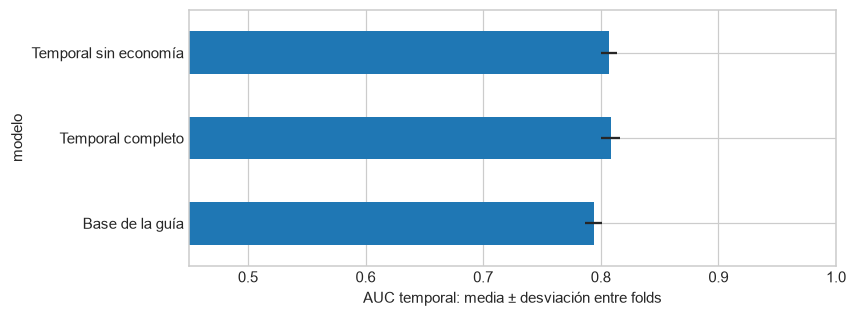

In [15]:
base_cv = evaluate(development, base_cols, folds, 'Base de la guía')
no_econ_cols = [c for c in feature_cols if c not in econ_cols]
no_econ_cv = evaluate(development, no_econ_cols, folds, 'Temporal sin economía')
comparison = pd.concat([base_cv, full_cv, no_econ_cv], ignore_index=True)
summary_cv = comparison.groupby('modelo').agg(auc_media=('auc_val', 'mean'), auc_sd=('auc_val', 'std'), ap_media=('ap_val', 'mean'))
comparison.to_csv(OUTPUT / 'validacion_principal.csv', index=False)
print(summary_cv.round(4).to_string())
fig, ax = plt.subplots(figsize=(8, 3))
summary_cv.auc_media.plot.barh(ax=ax, xerr=summary_cv.auc_sd)
ax.set(xlabel='AUC temporal: media ± desviación entre folds', xlim=(.45, 1))
plt.tight_layout(); plt.show()

**Respuesta:** AUC medio base = 0.7940; temporal completo = 0.8083; sin economía simulada = 0.8073. La diferencia temporal − base es +0.0143. La dispersión entre períodos importa: estos tres folds no son observaciones independientes y una diferencia pequeña no demuestra significación estadística.

## Parte 6: Feature Importance Analysis
### 6.1 Analizar Importancia de Features
Se ajusta un modelo con el desarrollo maduro anterior al test. La importancia por reducción de impureza describe ese modelo y puede favorecer variables continuas o correlacionadas. Para un control adicional se calcula permutation importance en el último fold de validación, no en test. No se usa ninguna importancia de test para elegir features.

Top 20:
 orders_90d                 0.4162
spend_90d                  0.0873
expanding_days_mean        0.0606
order_total                0.0402
spend_30d                  0.0315
recency_days               0.0240
cart_size                  0.0215
days_to_holiday            0.0184
day_of_month               0.0177
days_since_prior_lag_1     0.0165
order_number               0.0153
total_orders_so_far        0.0152
order_total_lag_2          0.0144
product_diversity_ratio    0.0135
order_total_lag_1          0.0120
unique_products            0.0112
days_since_prior_lag_2     0.0109
expanding_total_spent      0.0098
monetary_total             0.0094
monetary_avg               0.0089
Ventanas: {'7d': 0.0035, '30d': 0.037, '90d': 0.5035}
RFM: {'recency_days': 0.024, 'frequency': 0.0037, 'monetary_avg': 0.0089, 'monetary_total': 0.0094}


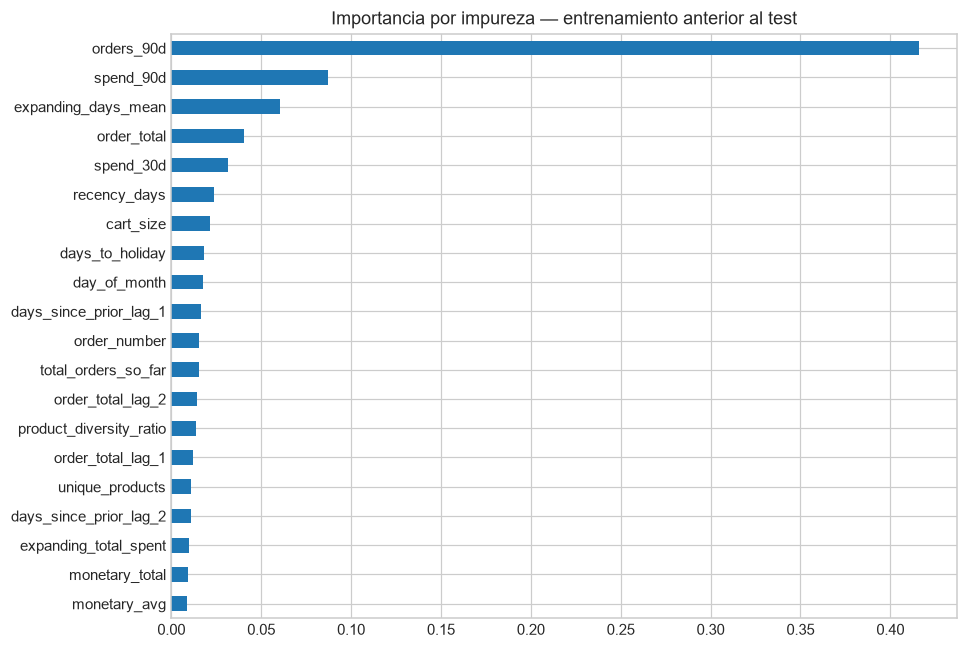

,feature,delta_auc,sd
26,orders_90d,0.079858,0.003276
27,spend_90d,0.011080,0.001241
15,expanding_days_mean,0.004915,0.000934
3,days_since_prior_lag_1,0.002617,0.000337
18,recency_days,0.002200,0.000614
25,spend_30d,0.001943,0.001567
1,order_total,0.001543,0.000232
30,product_diversity_ratio,0.001258,0.000915
4,days_since_prior_lag_2,0.000795,0.000346
10,order_total_lag_2,0.000726,0.000869


In [16]:
development_model = new_model().fit(final_train[feature_cols], final_train.will_purchase_again)
feature_names = development_model[0].get_feature_names_out(feature_cols)
raw_importance = pd.Series(development_model[1].feature_importances_, index=feature_names)
importance = raw_importance.reindex(feature_cols).fillna(0).sort_values(ascending=False)
importance.to_csv(OUTPUT / 'importancia_features.csv', header=['importancia'])
print('Top 20:\n', importance.head(20).round(4).to_string())
fig, ax = plt.subplots(figsize=(9, 6))
importance.head(20).sort_values().plot.barh(ax=ax)
ax.set(title='Importancia por impureza — entrenamiento anterior al test')
plt.tight_layout(); plt.show()
window_importance = pd.Series({f'{d}d': importance[[f'orders_{d}d', f'spend_{d}d']].sum() for d in [7, 30, 90]})
print('Ventanas:', window_importance.round(4).to_dict())
print('RFM:', importance[rfm_cols].round(4).to_dict())
last_tr, last_va = folds[-1]
fold_model = new_model().fit(development.loc[last_tr, feature_cols], development.loc[last_tr, 'will_purchase_again'])
permutation = permutation_importance(fold_model, development.loc[last_va, feature_cols], development.loc[last_va, 'will_purchase_again'], scoring='roc_auc', n_repeats=3, random_state=SEED, n_jobs=1)
perm_table = pd.DataFrame({'feature': feature_cols, 'delta_auc': permutation.importances_mean, 'sd': permutation.importances_std}).sort_values('delta_auc', ascending=False)
perm_table.to_csv(OUTPUT / 'permutation_validation.csv', index=False)
perm_table.head(12)

### 6.2 Análisis de Leakage Detection
Se verifica que cada fuente histórica sea anterior a la factura, que una publicación económica ya estuviera disponible y que los períodos de etiqueta de entrenamiento no alcancen validación. También se reconstruyen features con un prefijo del archivo y alterando el futuro: el pasado debe permanecer igual. Estos controles son más informativos que buscar palabras sospechosas en nombres de columnas.

In [17]:
assert (orders.loc[orders.history_max_date.notna(), 'history_max_date'] < orders.loc[orders.history_max_date.notna(), 'order_date']).all()
audit_users = orders.groupby('user_id').size().sort_values(ascending=False).head(8).index
audit = orders.loc[orders.user_id.isin(audit_users)].copy()
cut = audit.order_date.quantile(.65)
past = audit.loc[audit.order_date <= cut].copy()
historical_cols = lag_cols + rolling_cols + expanding_cols + rfm_cols + window_cols + diversity_cols + ['spend_slope', 'frequency_slope', 'history_max_date']
prefix_result = historical_features(past)
pd.testing.assert_frame_equal(audit.loc[past.index, historical_cols], prefix_result[historical_cols], check_dtype=False)
altered = audit.copy()
altered.loc[altered.order_date > cut, 'order_total'] *= 1000
altered.loc[altered.order_date > cut, 'cart_size'] += 10000
altered_result = historical_features(altered)
pd.testing.assert_frame_equal(audit.loc[past.index, historical_cols], altered_result.loc[past.index, historical_cols], check_dtype=False)
print('OK: fuentes anteriores; publicaciones disponibles; etiquetas purgadas; invariancia al truncar y alterar el futuro.')
toy = pd.DataFrame({'user_id': ['u'] * 4, 'order_id': ['a', 'b', 'c', 'd'],
    'order_date': pd.to_datetime(['2011-01-01', '2011-01-05', '2011-01-05', '2011-01-08']),
    'cart_size': [1, 2, 3, 4], 'order_total': [10., 20., 30., 40.],
    'products': [frozenset({x}) for x in ['a', 'b', 'c', 'd']],
    'countries': [frozenset({'UK'})] * 4})
toy_features = historical_features(toy)
assert toy_features.expanding_total_spent.tolist() == [0., 10., 10., 60.]
assert toy_features.orders_7d.tolist() == [0, 1, 1, 3]
assert toy_features.unique_products.tolist() == [0, 1, 1, 3]
print('OK: caso manual de facturas simultáneas y borde exacto de ventana.')
print('Brecha AUC train − validación por fold:', (full_cv.auc_train - full_cv.auc_val).round(4).tolist())

OK: fuentes anteriores; publicaciones disponibles; etiquetas purgadas; invariancia al truncar y alterar el futuro.
OK: caso manual de facturas simultáneas y borde exacto de ventana.
Brecha AUC train − validación por fold: [0.0852, 0.0819, 0.0818]


**Interpretación:** una brecha train/validación puede ser sobreajuste o cambio temporal; por sí sola no prueba leakage. Aquí se encontraron problemas en el procedimiento propuesto por la guía y se corrigieron antes de evaluar. Un AUC razonable tampoco demuestra automáticamente que no exista fuga. Estos checks cubren el flujo implementado, no garantizan que cualquier fuente externa sea correcta.

## Conclusiones y Reflexión
### Preguntas de Reflexión

**1. ¿Qué ventana parece más importante?** Sumando las importancias de frecuencia y gasto, gana **90d**, con 0.5035. Los resultados de las tres ventanas son {'7d': 0.0035, '30d': 0.037, '90d': 0.5035}. Se solapan y están correlacionadas; esta distribución no prueba que las otras ventanas sean prescindibles. Una ablation y la permutation importance de validación son controles adicionales.

**2. ¿Las variables económicas agregaron valor significativo?** La diferencia media de AUC al agregarlas fue +0.0009. No se puede afirmar significación con tres folds dependientes. Son datos simulados, compartidos por todos los usuarios de cada período: pueden actuar como proxies del mes, no como evidencia de un efecto económico real. Para producción se necesitarían series reales con su fecha de publicación y validación en otros períodos.

**3. ¿Qué RFM es más predictiva?** En este ajuste lidera `recency_days` (0.0240). Las importancias RFM son {'recency_days': 0.024, 'frequency': 0.0037, 'monetary_avg': 0.0089, 'monetary_total': 0.0094}. Frequency coincide con el conteo acumulado y Monetary comparte información con expanding: la importancia se reparte entre predictores redundantes. Recency describe el intervalo desde la compra previa, no una fecha de corte futura.

**4. ¿Señales de leakage y detección?** La guía usaba diversidad agregada sobre todo el archivo, recency contra su fecha final, indicadores sin publicación y etiquetas sin horizonte/maduración. Se reemplazaron por historia estricta, calendario disponible y labels de 30 días. Pasaron los controles de tiempos de fuente, disponibilidad, purga, truncamiento y perturbación de futuro. La brecha train/validación se analiza con la misma métrica AUC; no se compara accuracy con AUC.

**5. ¿Cómo desplegar diariamente?** Definir una hora de corte y el instante de predicción; actualizar por cliente contadores, ventanas y conjuntos históricos; recuperar datos externos por su fecha efectiva de disponibilidad; guardar snapshots para reconstruir features del pasado. Reentrenar con etiquetas que ya maduraron 30 días, validar hacia adelante y monitorear discriminación, calibración, drift y clientes nuevos. Este modelo predice después de una compra; para predecir cada día incluso sin factura hay que crear una tabla cliente-día y recalcular target/recency y población, en vez de reutilizar directamente estas filas.

##  Siguientes Pasos y Tareas Domiciliarias
### Opción 1: Probar con Otros Datasets — Olist (versión completa)
Se aplica la técnica a otro dataset real: Brazilian E-Commerce, `olistbr/brazilian-ecommerce`. Se descargó el dataset completo, y el ZIP de entrega incluye las tres tablas necesarias. La clave correcta para recompra es `customer_unique_id`: `customer_id` es específico de la orden. El target sigue siendo recompra dentro de 30 días; la unidad es una orden con ítems registrados, al momento de comprar; no se filtra por su estado final. No se utilizan fecha de entrega, reseñas ni información logística posterior.

Olist, Retail Rocket y H&M son las alternativas listadas en la consigna. Se ejecuta Olist como transferencia de la opción 1. Al final de esta sección se explican las adaptaciones requeridas para las otras dos; no se presentan como experimentos ejecutados.

In [18]:
olist_path = DATA / 'olist'
if not (olist_path / 'olist_orders_dataset.csv').exists():
    raise FileNotFoundError('Faltan las tres tablas Olist incluidas en la entrega.')
oo = pd.read_csv(olist_path / 'olist_orders_dataset.csv')
oc = pd.read_csv(olist_path / 'olist_customers_dataset.csv')
oi = pd.read_csv(olist_path / 'olist_order_items_dataset.csv')
olist_items = oi.groupby('order_id', as_index=False).agg(cart_size=('product_id', 'count'), order_total=('price', 'sum'), products=('product_id', lambda s: frozenset(s)))
ol = oo[['order_id', 'customer_id', 'order_purchase_timestamp']].merge(oc[['customer_id', 'customer_unique_id']], on='customer_id', validate='many_to_one').merge(olist_items, on='order_id', validate='one_to_one')
ol = ol.rename(columns={'customer_unique_id': 'user_id', 'order_purchase_timestamp': 'order_date'})
ol['order_date'] = pd.to_datetime(ol.order_date)
ol['countries'] = [frozenset({'Brazil'})] * len(ol)
ol = ol.drop(columns='customer_id').sort_values(['user_id', 'order_date', 'order_id']).reset_index(drop=True)
ol = calendar_features(historical_features(ol), country='BR')
# Se acota modeling al período estable, manteniendo las compras anteriores como historia.
ol = ol.loc[ol.order_date >= '2017-01-01'].reset_index(drop=True)
ol['next_order_date'] = pd.NaT
for _, g in ol.groupby('user_id', sort=False):
    t = g.order_date.to_numpy(dtype='datetime64[ns]')
    nxt = np.searchsorted(t, t, side='right')
    values = np.full(len(g), np.datetime64('NaT', 'ns'), dtype='datetime64[ns]')
    ok = nxt < len(g)
    values[ok] = t[nxt[ok]]
    ol.loc[g.index, 'next_order_date'] = values
ol['label_end'] = ol.order_date + HORIZON
ol['will_purchase_again'] = (ol.next_order_date.notna() & (ol.next_order_date <= ol.label_end)).astype(int)
ol = ol.loc[ol.label_end <= ol.order_date.max()].sort_values('order_date').reset_index(drop=True)
ol_cols = base_cols + ['recency_days', 'frequency', 'monetary_avg', 'monetary_total'] + window_cols + diversity_cols + calendar_cols
# En clientes con muy pocas compras la historia puede estar totalmente vacía en un fold.
ol_splits = list(temporal_splits(ol, n_splits=3))
olist_cv = evaluate(ol, ol_cols, ol_splits, 'Olist temporal')
olist_cv.to_csv(OUTPUT / 'olist_validacion.csv', index=False)
print('Olist: filas maduras:', len(ol), '| positivos:', int(ol.will_purchase_again.sum()), '| tasa:', round(ol.will_purchase_again.mean(), 4))
print(olist_cv[['fold', 'n_train', 'n_val', 'auc_val', 'ap_val']].round(4).to_string(index=False))

Olist: filas maduras: 92843 | positivos: 1316 | tasa: 0.0142
 fold  n_train  n_val  auc_val  ap_val
    1     7486  18984   0.5587  0.0217
    2    25629  31607   0.5539  0.0212
    3    54207  31266   0.5841  0.0217


**Resultado Olist:** AUC medio = 0.5656, AP medio = 0.0215, frente a una prevalencia global de 0.0142. La recompra es poco frecuente: accuracy sería engañosa porque predecir siempre “no” acertaría casi todas las filas. AP debe interpretarse junto a la prevalencia de cada período. Los mismos features no garantizan el mismo rendimiento cuando cambia el negocio.

**Retail Rocket — adaptación:** ordenar eventos por `visitorid` y timestamp; separar sesiones con gaps de 30 minutos; predecir conversión desde un prefijo de sesión, usando solamente eventos anteriores al corte. El target es una transacción posterior dentro del horizonte de sesión. No sumar el total de eventos de una sesión completa al inicio, ni usar su duración final. Mantener usuarios reales y purgar sesiones/horizontes que crucen folds.

**H&M — adaptación:** generar historiales por `customer_id`, artículo y fecha; calcular popularidad y frecuencia únicamente hasta el corte; usar ciclos de temporada y recomendar para la semana posterior. La evaluación cambia a ranking (por ejemplo MAP@12), con candidatos y negativos disponibles en ese corte. Aceptar personalmente las condiciones de la competencia y usar descarga autenticada; su volumen exige procesamiento por particiones. Es una tarea de recomendación distinta del clasificador binario de este notebook; no se inventan resultados para esos datos.

### Opción 2: Features Temporales Avanzadas
#### A. Features de Interacción Temporal
Se combina recency con frecuencia, se compara la tasa de compras de los últimos 7 días con los 23 días anteriores y se mide consistencia de intervalos. El cociente media/desvío es grande cuando los intervalos son estables; si el desvío es cero se limita el denominador para evitar infinito.
#### B. Features de Tendencias (Slope Features)
`spend_slope` usa una regresión gasto ~ día sobre las últimas diez facturas previas; `frequency_slope` aproxima la tasa mediante número acumulado de eventos ~ día. Ya se calcularon dentro de `historical_features`, siempre con fuentes anteriores.

In [19]:
orders['recency_frequency_interaction'] = orders.recency_days * orders.frequency
orders['purchase_acceleration'] = orders.orders_7d / 7 - (orders.orders_30d - orders.orders_7d) / 23
orders['temporal_consistency_ratio'] = orders.expanding_days_mean / orders.past_gap_std.clip(lower=1)
advanced_cols = ['recency_frequency_interaction', 'purchase_acceleration', 'temporal_consistency_ratio', 'spend_slope', 'frequency_slope']
orders[['order_date'] + advanced_cols].dropna().head(8)

,order_date,recency_frequency_interaction,purchase_acceleration,temporal_consistency_ratio,spend_slope,frequency_slope
4,2011-06-09 13:01:00,189.287500,0.000000,4.095429,-0.431690,0.016390
5,2011-08-02 08:48:00,215.297222,0.000000,5.813775,-1.265755,0.015992
6,2011-10-31 12:25:00,450.753472,0.000000,6.331303,-0.554571,0.016364
7,2011-12-07 15:52:00,222.862500,0.000000,4.108523,1.461138,0.015355
11,2011-09-25 13:13:00,519.304167,0.000000,2.554236,-4.015229,0.017785
17,2011-03-17 16:00:00,48.016667,-0.130435,0.711242,15.042450,0.114503
18,2011-03-22 16:08:00,20.022222,0.055901,1.142221,-6.950238,0.102474
19,2011-09-20 14:34:00,909.673611,0.000000,1.164297,-8.000573,0.111477


#### C. Features de Estacionalidad
Se incluyen dos armónicos anuales y temporadas del hemisferio norte. El archivo cubre poco más de un año: no permite estimar de forma confiable una descomposición anual con dos ciclos completos. Se demuestra `seasonal_decompose` con ciclo **semanal** y ventas diarias anteriores al test. Esa descomposición es un análisis retrospectivo y no entra como feature, porque el filtrado centrado puede consultar días posteriores al instante de cada observación.

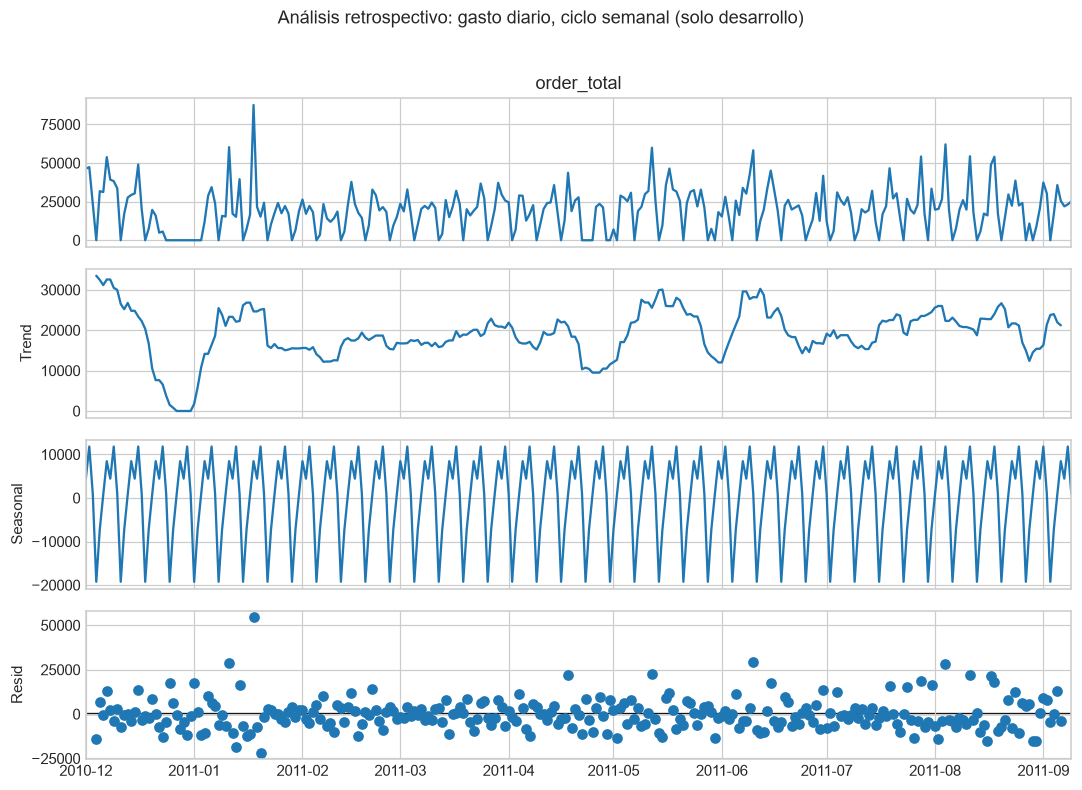

In [20]:
for harmonic in [1, 2]:
    phase = 2 * np.pi * harmonic * (orders.order_date.dt.dayofyear - 1) / 365.2425
    orders[f'annual_sin_{harmonic}'] = np.sin(phase)
    orders[f'annual_cos_{harmonic}'] = np.cos(phase)
    advanced_cols += [f'annual_sin_{harmonic}', f'annual_cos_{harmonic}']
orders['season'] = (orders.order_date.dt.month % 12 // 3).astype(int)
for season in range(4):
    orders[f'season_{season}'] = (orders.season == season).astype(int)
    advanced_cols.append(f'season_{season}')
daily = orders.loc[orders.order_date < test_start].set_index('order_date').resample('D').order_total.sum()
decomposition = seasonal_decompose(daily, model='additive', period=7)
fig = decomposition.plot()
fig.set_size_inches(10, 7)
fig.suptitle('Análisis retrospectivo: gasto diario, ciclo semanal (solo desarrollo)', y=1.02)
plt.tight_layout(); plt.show()

#### D. Features de Anomalías
El z-score del carrito monetario actual compara su total con la media y desvío del historial anterior. El total actual es conocido al cierre de factura. `IsolationForest` se ajusta exclusivamente con entrenamiento de cada fold; su score se agrega después a entrenamiento/validación usando ese mismo modelo. No se ajusta globalmente sobre el futuro.

In [21]:
orders['user_spend_zscore'] = (orders.order_total - orders.monetary_avg) / orders.past_spend_std.clip(lower=1)
advanced_cols += ['user_spend_zscore']
anomaly_columns = ['cart_size', 'order_total', 'orders_30d', 'spend_30d']
def anomaly_scores(train, other):
    imp = SimpleImputer(strategy='median', keep_empty_features=True)
    a = imp.fit_transform(train[anomaly_columns])
    b = imp.transform(other[anomaly_columns])
    detector = IsolationForest(n_estimators=100, contamination='auto', random_state=SEED, n_jobs=1).fit(a)
    return -detector.score_samples(a), -detector.score_samples(b)

train_anomaly, validation_anomaly = anomaly_scores(development.loc[last_tr], development.loc[last_va])
print('Score IsolationForest validación:', pd.Series(validation_anomaly).describe().round(3).to_dict())

Score IsolationForest validación: {'count': 2549.0, 'mean': 0.413, 'std': 0.086, 'min': 0.341, '25%': 0.357, '50%': 0.382, '75%': 0.427, 'max': 0.817}


#### E. Features de Cohort Analysis
La cohorte es el mes de primera compra **observada**, no una fecha de alta que este dataset no tiene. La edad se calcula desde esa fecha. El gasto actual se compara con la media de las facturas anteriores de su cohorte. Se agregan por timestamp antes de acumular para excluir todos los eventos simultáneos. Ningún cliente futuro participa antes de aparecer.

In [22]:
first_seen = orders.groupby('user_id').order_date.transform('min')
orders['cohort'] = first_seen.dt.to_period('M').astype(str)
orders['cohort_month'] = first_seen.dt.month
orders['account_age_months'] = (orders.order_date - first_seen).dt.total_seconds() / (86400 * 30.4375)
batch_cohort = orders.groupby(['cohort', 'order_date'], as_index=False).agg(cohort_spend=('order_total', 'sum'), cohort_count=('order_id', 'count')).sort_values(['cohort', 'order_date'])
batch_cohort['prior_spend'] = batch_cohort.groupby('cohort').cohort_spend.cumsum() - batch_cohort.cohort_spend
batch_cohort['prior_count'] = batch_cohort.groupby('cohort').cohort_count.cumsum() - batch_cohort.cohort_count
batch_cohort['cohort_prior_mean'] = batch_cohort.prior_spend / batch_cohort.prior_count.replace(0, np.nan)
orders = orders.merge(batch_cohort[['cohort', 'order_date', 'cohort_prior_mean']], on=['cohort', 'order_date'], validate='many_to_one')
orders['cohort_spend_ratio'] = orders.order_total / orders.cohort_prior_mean.replace(0, np.nan)
advanced_cols += ['cohort_month', 'account_age_months', 'cohort_spend_ratio']
orders[['order_date', 'cohort', 'account_age_months', 'cohort_spend_ratio']].head()

,order_date,cohort,account_age_months,cohort_spend_ratio
0,2011-01-18 10:01:00,2011-01,0.000000,148.872189
1,2010-12-07 14:57:00,2010-12,0.000000,1.912429
2,2011-01-26 14:30:00,2010-12,1.642094,1.067760
3,2011-04-07 10:43:00,2010-12,3.969564,1.358810
4,2011-06-09 13:01:00,2010-12,6.042528,0.817225


#### F. Features de Sesión y Secuencias
Tiempo desde la primera compra observada, velocidad de gasto histórico por día y tiempo desde la compra anterior. Se cuentan grupos de compras separados por más de 30 minutos como **sesiones de compra aproximadas**. Online Retail no tiene clics ni navegación: no podemos inferir sesiones web, intención o conversión de sesión. La duración final de una sesión tampoco se conoce mientras está en curso.

In [23]:
orders['spending_velocity'] = orders.expanding_total_spent / orders.time_since_first_purchase.clip(lower=1)
orders['inactivity_gap'] = orders.recency_days
advanced_cols += ['time_since_first_purchase', 'spending_velocity', 'inactivity_gap', 'purchase_sessions_so_far']
advanced_cols = list(dict.fromkeys(advanced_cols))
assert np.isfinite(orders[advanced_cols].to_numpy()[~np.isnan(orders[advanced_cols].to_numpy())]).all()
# Reconstruir las mismas poblaciones tras añadir columnas, conservando índices cronológicos.
eligible_plus = orders.loc[orders.label_end <= observed_end].sort_values('order_date').reset_index(drop=True)
dev_plus = eligible_plus.loc[eligible_plus.label_end < test_start].copy()
test_plus = eligible_plus.loc[eligible_plus.order_date >= test_start].copy()
assert development.order_id.tolist() == dev_plus.order_id.tolist()
assert development.label_end.max() < test_start
plus_cols = feature_cols + advanced_cols
advanced_cv = evaluate(dev_plus, plus_cols, folds, 'Temporal avanzado A–F')
anomaly_rows = []
for fold, (tr, va) in enumerate(folds, 1):
    train, val = dev_plus.loc[tr].copy(), dev_plus.loc[va].copy()
    train['anomaly_score'], val['anomaly_score'] = anomaly_scores(train, val)
    model = new_model().fit(train[plus_cols + ['anomaly_score']], train.will_purchase_again)
    anomaly_rows.append({'fold': fold, 'auc_val': roc_auc_score(val.will_purchase_again, model.predict_proba(val[plus_cols + ['anomaly_score']])[:, 1])})
anomaly_cv = pd.DataFrame(anomaly_rows)
advanced_cv.to_csv(OUTPUT / 'validacion_features_avanzadas.csv', index=False)
print('Temporal principal:', full_cv.auc_val.mean())
print('Features A–F:', advanced_cv.auc_val.mean())
print('Features A–F + IsolationForest:', anomaly_cv.auc_val.mean())

Temporal principal: 0.8082684400122012
Features A–F: 0.8085031264980665
Features A–F + IsolationForest: 0.8092649922908937


**Respuesta de exploración:** las features A–F cambian el AUC medio de 0.8083 a 0.8085; agregando el score de IsolationForest se obtiene 0.8093. La complejidad extra se justifica solamente si el beneficio se repite en otros cortes y compensa mantenimiento y costo. La descomposición retrospectiva no se filtró al clasificador.

### Opción 3: Técnicas de Validación Avanzadas
**Blocked:** entrenamiento en el bloque inmediatamente anterior, validación en el siguiente, con maduración de labels. **Walk-forward:** historia acumulada y siguiente bloque futuro. **Purged:** walk-forward con eliminación de intervalos de etiquetas que alcanzan validación y un embargo adicional de siete días antes del corte.

Un Purged K-Fold genérico puede entrenar a ambos lados del fold validado; eso no representa el despliegue cronológico de este problema. Aquí se implementa su variante **forward**, sin entrenar con el futuro. Los esquemas son comparaciones de protocolos, no otra búsqueda usando test. Todos excluyen fechas del test principal.

In [24]:
def advanced_splits(frame, scheme, n_blocks=5):
    days = np.sort(frame.order_date.dt.normalize().unique())
    blocks = np.array_split(days, n_blocks)
    for i in range(2, n_blocks):
        start = pd.Timestamp(blocks[i][0])
        end = pd.Timestamp(blocks[i][-1]) + pd.Timedelta(days=1)
        begin = pd.Timestamp(blocks[i-1][0]) if scheme == 'Blocked' else pd.Timestamp(days[0])
        embargo = pd.Timedelta(days=7) if scheme == 'Purged forward + embargo' else pd.Timedelta(0)
        tr = frame.index[(frame.order_date >= begin) & (frame.label_end < start - embargo)].to_numpy()
        va = frame.index[(frame.order_date >= start) & (frame.order_date < end)].to_numpy()
        assert frame.loc[tr, 'label_end'].max() < frame.loc[va, 'order_date'].min()
        yield tr, va

advanced_validation = pd.concat([evaluate(development, feature_cols, list(advanced_splits(development, scheme)), scheme)
    for scheme in ['Blocked', 'Walk-forward', 'Purged forward + embargo']], ignore_index=True)
advanced_validation.to_csv(OUTPUT / 'validacion_protocolos.csv', index=False)
print(advanced_validation[['modelo', 'fold', 'n_train', 'n_val', 'auc_val']].round(4).to_string(index=False))
print('Promedios:\n', advanced_validation.groupby('modelo').auc_val.agg(['mean', 'std']).round(4))

                  modelo  fold  n_train  n_val  auc_val
                 Blocked     1      569   2276   0.8108
                 Blocked     2     1050   2341   0.8107
                 Blocked     3     1060   2007   0.8011
            Walk-forward     1     2845   2276   0.8114
            Walk-forward     2     5071   2341   0.8118
            Walk-forward     3     7357   2007   0.8049
Purged forward + embargo     1     2649   2276   0.8077
Purged forward + embargo     2     4788   2341   0.8167
Purged forward + embargo     3     6992   2007   0.8103
Promedios:
                             mean     std
modelo                                  
Blocked                   0.8075  0.0056
Purged forward + embargo  0.8115  0.0046
Walk-forward              0.8094  0.0039


### Decisión final y evaluación de test
Se elige entre base, temporal sin economía, temporal completo y avanzado según el AUC medio de los mismos folds. Se incluye el candidato con IsolationForest en esa comparación. Ante empate práctico, se prefiere menor complejidad (los resultados exactos de la tabla permiten revisar esa elección). El test se evalúa una sola vez después de decidir y no se usa para agregar/quitar columnas.

In [25]:
candidate_columns = {'Base de la guía': base_cols, 'Temporal sin economía': no_econ_cols,
                     'Temporal completo': feature_cols, 'Temporal avanzado A–F': plus_cols,
                     'Avanzado + IsolationForest': plus_cols + ['anomaly_score']}
candidate_scores = {'Base de la guía': base_cv.auc_val.mean(), 'Temporal sin economía': no_econ_cv.auc_val.mean(),
                    'Temporal completo': full_cv.auc_val.mean(), 'Temporal avanzado A–F': advanced_cv.auc_val.mean(),
                    'Avanzado + IsolationForest': anomaly_cv.auc_val.mean()}
best_auc = max(candidate_scores.values())
# Regla establecida antes del test: dentro de 0.005 AUC del mejor, menor cantidad de columnas.
chosen = min((name for name in candidate_scores if candidate_scores[name] >= best_auc - .005), key=lambda name: len(candidate_columns[name]))
chosen_cols = candidate_columns[chosen]
train_final_plus = dev_plus.loc[dev_plus.label_end < test_start].copy()
test_final_plus = test_plus.copy()
if 'anomaly_score' in chosen_cols:
    train_final_plus['anomaly_score'], test_final_plus['anomaly_score'] = anomaly_scores(train_final_plus, test_final_plus)
final_model = new_model().fit(train_final_plus[chosen_cols], train_final_plus.will_purchase_again)
test_probability = final_model.predict_proba(test_final_plus[chosen_cols])[:, 1]
test_auc = roc_auc_score(test_final_plus.will_purchase_again, test_probability)
test_ap = average_precision_score(test_final_plus.will_purchase_again, test_probability)
print('AUC de selección:', {k: round(v, 4) for k, v in candidate_scores.items()})
print('Elegido antes del test:', chosen)
print('Test AUC:', round(test_auc, 4), '| AP:', round(test_ap, 4), '| prevalencia:', round(test_final_plus.will_purchase_again.mean(), 4))
print(classification_report(test_final_plus.will_purchase_again, test_probability >= .5, digits=3))
pd.DataFrame({'order_id': test_final_plus.order_id, 'order_date': test_final_plus.order_date,
              'y': test_final_plus.will_purchase_again, 'probabilidad': test_probability}).to_csv(OUTPUT / 'predicciones_test.csv', index=False)
pd.DataFrame([{'modelo': chosen, 'auc_test': test_auc, 'ap_test': test_ap, 'n_test': len(test_final_plus)}]).to_csv(OUTPUT / 'resultado_test.csv', index=False)

AUC de selección: {'Base de la guía': np.float64(0.794), 'Temporal sin economía': np.float64(0.8073), 'Temporal completo': np.float64(0.8083), 'Temporal avanzado A–F': np.float64(0.8085), 'Avanzado + IsolationForest': np.float64(0.8093)}
Elegido antes del test: Temporal sin economía
Test AUC: 0.7843 | AP: 0.8107 | prevalencia: 0.4869
              precision    recall  f1-score   support

           0      0.693     0.813     0.748      1996
           1      0.758     0.620     0.682      1894

    accuracy                          0.719      3890
   macro avg      0.725     0.716     0.715      3890
weighted avg      0.725     0.719     0.716      3890



**Resultado final:** se eligió **Temporal sin economía** usando validación y la regla de simplicidad (tolerancia 0,005 AUC). En 3890 facturas del período futuro reservado, AUC = **0.7843** y AP = **0.8107**. El umbral 0,5 es ilustrativo; una campaña real elegiría el umbral con costos/beneficios usando validación y comprobaría calibración. El test mide otros momentos de los mismos clientes observados, no necesariamente generalización a clientes completamente nuevos.

